# **ROTATING EQUIPMENT ANOMALY DETECTION**
During the Anomaly Detection phase, the algorithm identifies samples in data set which differ from the normal
operation condition.
We worked on data collected by ENI on rotating machines.


### Configuration variable

This two variable let you choose the machine to analyze and the type of training split to do.
the training modes are the following
1. "train_old test_new" all the old data is used as training and the new is used as testing
2. "train_new test_new" all the new data is used as training and the new is used as testing
3. "train_old test old" all the old data is used as training and the old is used as testing
4. "train_old+new test new" all the old data + 50% of the new data is used as training and the remaining new data is used as testing

In [1]:
# All machines: V470MT001A (Old+New),  V360KB011E(Old+new), V360KB011B (New) 
MACHINE_NAME = "V360KB011E" #this variable let you change the machine you want to analyze
training_mode = "train_old test_old" #this variable let you change the configuration of the train and test split

In [2]:
import sys
import numpy as np
import pandas as pd
from datetime import datetime
from sklearn.preprocessing import StandardScaler


def consider_range(noc_data, sensor_data):
    ''' 1. creation of the sensor data training filtering the intervals present in noc data '''
    sensor_data_training = pd.DataFrame()
    sensor_data['sensor_ts'] = pd.to_datetime(sensor_data['sensor_ts'], format='%Y-%m-%d %H:%M:%S')
    for  a in noc_data[['range_start', 'range_end']].values:
        range_str = (a[0], a[1])
        sensor_data_temp = sensor_data[(sensor_data['sensor_ts'] >= datetime.strptime(range_str[0], "%Y-%m-%d %H:%M:%S")) & (sensor_data['sensor_ts'] <= datetime.strptime(range_str[1], "%Y-%m-%d %H:%M:%S"))]
        sensor_data_training = pd.concat([sensor_data_training, sensor_data_temp])
    return sensor_data_training


def add_labels(sensor_data, sensor_data_training, labels='NOC'):
    sensor_data[labels] = 0
    sensor_data.loc[sensor_data['sensor_ts'].isin(sensor_data_training['sensor_ts']), labels] = 1
    return sensor_data


def cut_col(train_card):
    ''' cut columns from G to J and column tag_id'''
    train_card = train_card.drop(columns = [*train_card.columns[6:10], 'tag_id'])
    return train_card


def import_datasets(name_machine, IN_COLAB):
    '''Import required datasets. It depends on the machine considered'''
    dataset_folder_old = dataset_folder_new = dataset_folder = ""

    if name_machine == 'V470MT001A':
        if IN_COLAB:
          # old data
          dataset_folder_old = f"/content/drive/MyDrive/AI_Industry_Data/old_data/train_V470MT001A_idtraining_889/"
          # new data
          dataset_folder_new = f"/content/drive/MyDrive/AI_Industry_Data/new_data/V470MT001A/"

        # old data
        noc_data_old = pd.read_csv(dataset_folder_old + f"noc_data_{name_machine}_889.csv",sep=",")
        sensor_data_old = pd.read_csv(dataset_folder_old + f"sensor_data_{name_machine}_889.csv",sep=",")
        sensor_data_old.drop(['COVA.ABB.V470-A018-A.pv', 'COVA.ABB.V470-A028-A.pv'], axis=1, inplace=True) # removing two sensors beacuse thery're missing in new data
        train_card = pd.read_csv(dataset_folder_old + f"train_card_{name_machine}_889.csv",sep=",")

        # new data
        confirmed_anomalies_new = pd.read_excel(dataset_folder_new + f"MT001A_confirmed_anomalies.xlsx")
        sensor_data_new = pd.read_csv(dataset_folder_new + f"MT001A_sensorsdata_new.csv", sep=",")
        confirmed_anomalies_new.rename(columns={'anomaly_start': 'range_start', 'anomaly_end': 'range_end'}, inplace=True)
        confirmed_anomalies_new["range_start"] = confirmed_anomalies_new.apply(lambda x : str(x["range_start"]),axis=1)
        confirmed_anomalies_new["range_end"] = confirmed_anomalies_new.apply(lambda x : str(x["range_end"]),axis=1)

        # Cols to consider
        target_cols = list(set(sensor_data_old.columns) & set(sensor_data_new.columns)) # since the old and the new data have some columns that dont match, we consider only the common columns
        sensor_data_old = sensor_data_old[target_cols]
        sensor_data_new = sensor_data_new[target_cols]
        target_cols.remove('sensor_ts')

        # casting time stamps
        sensor_data_new["sensor_ts"] = sensor_data_new.apply(lambda x : x["sensor_ts"].replace("T", " ")[:-6],axis=1)

        # adding NOC label based on NOC intervals - old data
        sensor_data_training = consider_range(noc_data_old, sensor_data_old)
        sensor_data_old = add_labels(sensor_data_old, sensor_data_training, labels = 'NOC')
        # columns reordering
        sensor_data_old = sensor_data_old.loc[:, ['sensor_ts'] + target_cols + ['NOC']]
        # adding anomaly label based on anomaly intervals - new data
        sensor_data_testing = consider_range(confirmed_anomalies_new, sensor_data_new)
        sensor_data_new = add_labels(sensor_data_new, sensor_data_testing, labels='anomaly')
        # columns reordering
        sensor_data_new = sensor_data_new.loc[:, ['sensor_ts'] + target_cols + ['anomaly']]

    if name_machine == 'V360KB011E':
        if IN_COLAB:
          # old data
          dataset_folder_old = f"/content/drive/MyDrive/AI_Industry_Data/old_data/train_V360KB011E_idtraining_849/"
          # new data
          dataset_folder_new = f"/content/drive/MyDrive/AI_Industry_Data/new_data/V360KB11E/"

        # old data
        noc_data_old = pd.read_csv(dataset_folder_old + f"noc_data_{name_machine}_849.csv", sep=",")
        sensor_data_old = pd.read_csv(dataset_folder_old + f"sensor_data_{name_machine}_849.csv", sep=",")
        train_card = pd.read_csv(dataset_folder_old + f"train_card_{name_machine}_849.csv", sep=",")

        # new data
        confirmed_anomalies_new = pd.read_excel(dataset_folder_new + f"11E_confirmed_anomalies.xlsx")
        sensor_data_new = pd.read_csv(dataset_folder_new + f"11E_sensorsdata_new.csv", sep=",")
        confirmed_anomalies_new.rename(columns={'anomaly_start': 'range_start', 'anomaly_end': 'range_end'}, inplace=True)
        confirmed_anomalies_new["range_start"] = confirmed_anomalies_new.apply(lambda x: str(x["range_start"]), axis=1)
        confirmed_anomalies_new["range_end"] = confirmed_anomalies_new.apply(lambda x: str(x["range_end"]), axis=1)

        # Cols to consider
        target_cols = list(set(sensor_data_old.columns) & set(
            sensor_data_new.columns))  # since the old and the new data have some columns that dont match, we consider only the common columns
        sensor_data_old = sensor_data_old[target_cols]
        sensor_data_new = sensor_data_new[target_cols]
        target_cols.remove('sensor_ts')

        # casting time stamps
        sensor_data_new["sensor_ts"] = sensor_data_new.apply(lambda x: x["sensor_ts"].replace("T", " ")[:-6],
                                                             axis=1)

        # adding NOC label based on NOC intervals - old data
        sensor_data_noc = consider_range(noc_data_old, sensor_data_old)
        sensor_data_old = add_labels(sensor_data_old, sensor_data_noc, labels='NOC')
        # columns reordering
        sensor_data_old = sensor_data_old.loc[:, ['sensor_ts'] + target_cols + ['NOC']]
        # adding anomaly label based on anomaly intervals - new data
        sensor_data_anomalies = consider_range(confirmed_anomalies_new, sensor_data_new)
        sensor_data_new = add_labels(sensor_data_new, sensor_data_anomalies, labels='anomaly')
        # columns reordering
        sensor_data_new = sensor_data_new.loc[:, ['sensor_ts'] + target_cols + ['anomaly']]

    if name_machine == 'V360KB011B':

        if IN_COLAB:
            dataset_folder = f"/content/drive/MyDrive/AI_Industry_Data/new_data/V360KB011B/"  # CHANGE HERE THE DATA FOLDER

        noc_data = pd.read_csv(dataset_folder + f"noc_data_{name_machine}_111.csv", sep=";")
        sensor_data_new = pd.read_csv(dataset_folder + f"11B_sensorsdata_new.csv", sep=",")
        train_card = pd.read_csv(dataset_folder + f"train_card_{name_machine}_111.csv", sep=";")
        confirmed_anomalies = pd.read_excel(dataset_folder + f"11B_confirmed_anomalies.xlsx")
        confirmed_anomalies.rename(columns={'anomaly_start': 'range_start', 'anomaly_end': 'range_end'}, inplace=True)
        confirmed_anomalies["range_start"] = confirmed_anomalies.apply(lambda x: str(x["range_start"]), axis=1)
        confirmed_anomalies["range_end"] = confirmed_anomalies.apply(lambda x: str(x["range_end"]), axis=1)

        # Cols to consider
        target_cols = sensor_data_new.columns[1:]

        # casting time stamps
        sensor_data_new["sensor_ts"] = sensor_data_new.apply(lambda x: x["sensor_ts"].replace("T", " ")[:-6],
                                                             axis=1)
        # adding NOC label based on NOC intervals - old data
        sensor_data_noc = consider_range(noc_data, sensor_data_new)
        sensor_data_new = add_labels(sensor_data_new, sensor_data_noc, labels='NOC')
        # adding anomaly label based on anomaly intervals - new data
        sensor_data_anomaly = consider_range(confirmed_anomalies, sensor_data_new)
        sensor_data_new = add_labels(sensor_data_new, sensor_data_anomaly, labels='anomaly')
        
        # columns reordering --- Already ordered
        # sensor_data_new = sensor_data_new.loc[:, ['sensor_ts'] + target_cols + ['NOC','anomaly']]

        sensor_data_old = pd.DataFrame(columns=sensor_data_new.columns)

        return noc_data, sensor_data_old, train_card, confirmed_anomalies, sensor_data_new, target_cols

    # eliminate useless colums from train card
    train_card = cut_col(train_card)

    return noc_data_old, sensor_data_old, train_card, confirmed_anomalies_new, sensor_data_new,target_cols


def compute_noc_nnoc_distance(sensor_data, target_cols, target, method='wasserstein', sample_n = 100):
    if not sensor_data.empty:
      distance = None
      if method == 'wasserstein':
          distance = sp.stats.wasserstein_distance_nd(sensor_data[sensor_data[target] == 1][target_cols].sample(sample_n,random_state=42),sensor_data[sensor_data[target] == 0][target_cols].sample(sample_n,random_state=42))
      elif method == 'jensen-shannon':
          distance = sp.spatial.distance.jensenshannon(sensor_data[sensor_data[target] == 1][target_cols].sample(sample_n,random_state=42),sensor_data[sensor_data[target] == 0][target_cols].sample(sample_n,random_state=42))
          distance = pd.Series(distance).replace([np.inf, -np.inf], np.nan).dropna()
          distance = distance.mean()
    else:
      distance = '/'

    return distance

def drop_offline_time_ranges(train_card, sensor_data):
    if not sensor_data.empty:
      data_to_remove = train_card[train_card['onoff_parameter']== 1 ][['boot_threshold','id_sensor']].groupby('id_sensor').first().reset_index()
      for i in range(len(data_to_remove)):
        dtr = data_to_remove.iloc[i]
        sensor_data = sensor_data.drop(np.where(sensor_data[dtr['id_sensor']] <= dtr['boot_threshold'])[0])
    return sensor_data

def drop_nan(sensor_data, target_cols):
    if not sensor_data.empty:
      # Drop columns and rows where all values are NaN
      sensor_data.dropna(axis=0, how='all', subset=target_cols, inplace=True)
      sensor_data.dropna(axis=1, how='all', inplace=True)

      # Drop rows with NaN values
      sensor_data = sensor_data.dropna()

      # Reset the index
      sensor_data.reset_index(drop=True, inplace=True)

    return sensor_data


def scale_data(train_df, test_df):
    # Initialize the StandardScaler
    scaler = StandardScaler()

    if "NOC" in train_df.columns:
      target_train = "NOC"
    else:
      target_train = "anomaly"

    if "NOC" in test_df.columns:
      target_test = "NOC"
    else:
      target_test = "anomaly"

    # TRAIN DATA
    train_data = train_df.drop(['sensor_ts', target_train], axis=1)
    train_ts = train_df['sensor_ts']
    target_train_column = train_df[target_train]
    # Fit the Scaler with train_data
    scaler.fit(train_data)
    # Transform data usign the fitted Scaler
    scaled_train_data = scaler.transform(train_data)
    # Convert the scaled data back to a DataFrame
    scaled_train_data_df = pd.DataFrame(scaled_train_data, index=train_data.index, columns=train_data.columns)
    scaled_train_data_df.insert(0, 'sensor_ts', train_ts)
    scaled_train_data_df[target_train] = target_train_column.values
    # index reset
    scaled_train_data_df = scaled_train_data_df.reset_index(drop = True)

    # TEST DATA
    test_data = test_df.drop(['sensor_ts', target_test], axis=1)
    test_ts = test_df['sensor_ts']
    target_test_column = test_df[target_test]
    # Transform data usign the alredy fitted Scaler
    scaled_test_data = scaler.transform(test_data)
    # Convert the scaled data back to a DataFrame
    scaled_test_data_df = pd.DataFrame(scaled_test_data, index=test_data.index, columns=test_data.columns)
    scaled_test_data_df.insert(0, 'sensor_ts', test_ts)
    scaled_test_data_df[target_test] = target_test_column.values
    # index reset
    scaled_test_data_df = scaled_test_data_df.reset_index(drop = True)

    return scaled_train_data_df, scaled_test_data_df


def plot_columns_in_grid(scaled_train_df, target_cols):
    n_cols = len(target_cols)
    n_rows = n_cols // 3 + (n_cols % 3 > 0)
    fig, axs = plt.subplots(n_rows, 3, figsize=(15, 5 * n_rows))

    for i, col in enumerate(target_cols):
        row = i // 3
        col_idx = i % 3
        axs[row, col_idx].plot(scaled_train_df[col])
        axs[row, col_idx].set_title(col)

    # Hide x labels and tick labels for top plots and y ticks for right plots.
    for ax in axs.flat:
        ax.label_outer()

def train_test_split(sensor_data_old,sensor_data_new,training_mode):
    # Traing and Testing datasets
    if MACHINE_NAME == "V360KB011B" and training_mode == "train_new test_new":
            train_df = sensor_data_new[:int(len(sensor_data_new)*0.8)][sensor_data_new['NOC'] == 1 or sensor_data_new['anomaly'] == 0]
            test_df = pd.concat([sensor_data_new[:int(len(sensor_data_new)*0.8)][sensor_data_new['NOC'] == 0 or sensor_data_new['anomaly'] == 1], sensor_data_new[int(len(sensor_data_new)*0.8):]])
            target = "anomaly"
    elif MACHINE_NAME == "V360KB011B" and training_mode != "train_new test_new":
        assert("This machine has only new data")
        return
    else:
        if training_mode == "train_old+new test_new":
            train_df = pd.concat([sensor_data_old[sensor_data_old['NOC'] == 1],sensor_data_new[sensor_data_new['anomaly'] == 0][:int(len(sensor_data_new)*0.5)]])
            test_df = sensor_data_new[int(len(sensor_data_new)*0.5):]
            train_df = train_df.drop("anomaly",axis=1)
            target = "anomaly"
        elif training_mode == "train_old test_old":
            train_df = sensor_data_old[:int(len(sensor_data_old)*0.8)][sensor_data_old['NOC'] == 1]
            test_df = pd.concat([sensor_data_old[:int(len(sensor_data_old)*0.8)][sensor_data_old['NOC'] == 0], sensor_data_old[int(len(sensor_data_old)*0.8):]])
            target = "NOC"
        elif training_mode == "train_new test_new":
            train_df = sensor_data_new[:int(len(sensor_data_new)*0.8)][sensor_data_new['anomaly'] == 0]
            test_df = pd.concat([sensor_data_new[:int(len(sensor_data_new)*0.8)][sensor_data_new['anomaly'] == 1], sensor_data_new[int(len(sensor_data_new)*0.8):]])
            target = "anomaly"
        elif training_mode == "train_old test_new":
            train_df = sensor_data_old[sensor_data_old['NOC'] == 1]
            test_df = sensor_data_new
            target = "anomaly"


    return train_df, test_df,target


## Setup

In [3]:
!pip install scikit-optimize
!pip install tqdm
!pip install gdown

### Downloading Models 

In [4]:
try:
  from google.colab import drive
  drive.mount('/content/drive/', force_remount=True)
  IN_COLAB = True
except:
  IN_COLAB = False
if not IN_COLAB:
    #download AE_LSTM
    !gdown --id 1SC5OEYKZ2QOPrvaRCYdYKC3apRDdZbZZ
    #download AE
    !gdown --id 1yNZFDnNUaDPCkITQXSmljk0oFqStjxsu
    #download VAE_LSTM
    !gdown --id 1ybV48nvxzq5jAyPQH6JOPux6SgNRb-_5
    #download VAE
    !gdown --id 1wAAXlv6vvjzJgoexHou1QDHYl8r2fKNG
    #download utils.py
    !gdown --id 1-mZDH0qt7qkf6lHeW9HoVYdkf0MOid-a

if not IN_COLAB:
    !mkdir models
    !mv AE.py models
    !mv AE_LSTM.py models
    !mv VAE.py models
    !mv VAE_LSTM.py models

/usr/local/lib/python3.10/dist-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1SC5OEYKZ2QOPrvaRCYdYKC3apRDdZbZZ
From (redirected): https://drive.google.com/uc?id=1SC5OEYKZ2QOPrvaRCYdYKC3apRDdZbZZ&confirm=t&uuid=fad9806d-c5b5-442e-8782-2c7b8214beb6
To: /kaggle/working/AE_LSTM.py
100%|██████████████████████████████████████| 5.73k/5.73k [00:00<00:00, 23.3MB/s]
/usr/local/lib/python3.10/dist-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1yNZFDnNUaDPCkITQXSmljk0oFqStjxsu
From (redirected): https://drive.google.com/uc?id=1yNZFDnNUaDPCkITQXSmljk0oFqStjxsu&confirm=t&uuid=b8f952c8-c6a0-46c

### Imports

In [5]:
import sys
if IN_COLAB:
    sys.path.append('/content/drive/MyDrive/AI_Industry_Data/AI_Industry_Davide_Luca_Guglielmo_14_10_2024')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from utils import *
from models.AE import AE
from models.AE_LSTM import AE_LSTM
from models.VAE import VAE
from models.VAE_LSTM import VAE_LSTM
from sklearn.preprocessing import StandardScaler
from datetime import datetime
import torch.nn.functional as F
import torch
from tqdm import tqdm
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import mean_squared_error

from sklearn.metrics import f1_score
from sklearn.model_selection import KFold
from skopt import gp_minimize
from skopt.space import Real
# Create my DatasetClass
from torch.utils.data import DataLoader,Dataset
from torch import nn
import scipy as sp

In [6]:
figsize=(18, 6)

# Machine code:

## Dataset download


In [7]:
if not IN_COLAB and MACHINE_NAME == "V360KB011B":
    #download confirmed anomalies
    !gdown --id 1RHQDSd2YhY7qB4n-xhxEbZqilWr4V3aT
    #download new sensro data
    !gdown --id 1H1YJ9Bpxj-BgM9VlwCPvogaAZNYJMNs5
    #download noc data
    !gdown --id 11uYSF7DnguUWJrWXTxPD7mhxEZa0HiId
    #download old train card
    !gdown --id 12xCHG6aK90i1JWB4gytj-01LfwJDYhxA

In [8]:
if not IN_COLAB and MACHINE_NAME == "V360KB011E":
    #download confirmed anomalies
    !gdown --id 1BfvvJkLRM64KDlkQhW652_tgbRhvCbNO
    #download new sensro data
    !gdown --id 1w5APjZPHbNbrDS31-3ePp3JDDCZvPfvu
    #download old noc data
    !gdown --id 106HVUjSv_5K3v3N9RksIMRCZiAWz4_qa
    #download old sensor data
    !gdown --id 10DrYxur5-zgDOuJb7XpUS3A8hd1Kf3JT
    #download old train card
    !gdown --id 10RnRfOTi_XLo2nzBcva3X0cOzssFp3cB

/usr/local/lib/python3.10/dist-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1BfvvJkLRM64KDlkQhW652_tgbRhvCbNO
To: /kaggle/working/11E_confirmed_anomalies.xlsx
100%|██████████████████████████████████████| 13.5k/13.5k [00:00<00:00, 38.9MB/s]
/usr/local/lib/python3.10/dist-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1w5APjZPHbNbrDS31-3ePp3JDDCZvPfvu
From (redirected): https://drive.google.com/uc?id=1w5APjZPHbNbrDS31-3ePp3JDDCZvPfvu&confirm=t&uuid=f8ba0754-756d-4cba-a3a4-b326c97d937c
To: /kaggle/working/11E_sensorsdata_new.csv
100%|█████████████████████████████████████████| 380M/380M [00:02<

In [9]:
if not IN_COLAB and MACHINE_NAME == "V470MT001A":
    #download confirmed anomalies
    !gdown --id 1tZq98OjAkBRj5XnxauzBvLKgvqJRpY6t
    #download new sensor data
    !gdown --id 1yprWH02yQ7MRsFElaT_4Ja43eyKCL5CA
    #download old noc data
    !gdown --id 10YpZkZHPMgfTq_NpYnETzoSuiW_l9Cxx
    #download old sensor data
    !gdown --id 10_aDjg82rPJ2SMjGrpkIjGY-F_okQLaf
    #download old train card
    !gdown --id 10_ou_w4rt6QrSN1j7efDJm4_1U9jyZnE

In [10]:
noc_data_old, sensor_data_old, train_card, confirmed_anomalies_new, sensor_data_new, target_cols = import_datasets(MACHINE_NAME, IN_COLAB)

`noc_data` contains the time intervals in which we assumes there are not anomalies (NOC == _Normal Operating Conditions_).

In [11]:
noc_data_old.head()

,id_training,range_start,range_end,id_train
0,849,2022-11-26 00:00:00,2022-12-11 13:20:00,V360KB011E
1,849,2022-12-12 18:24:30,2022-12-22 23:50:00,V360KB011E
2,849,2023-01-29 04:14:30,2023-02-24 00:20:00,V360KB011E
3,849,2023-02-24 17:04:30,2023-07-19 00:00:00,V360KB011E


`confirmed_anomalies` contains the time intervals in which we know there are anomalies.

In [12]:
confirmed_anomalies_new.head()

,range_start,range_end
0,2024-11-05 00:00:00,2024-11-06 00:00:00
1,2024-11-15 00:00:00,2024-11-20 00:00:00


Each row in `train_card` contains the information about each sensor found in `sensor_data`.

In [13]:
train_card.head()

,id_train,asset_id,train_type,equipment_type,id_sensor,unit,sensor_description,priority,for_ml,onoff_parameter,boot_threshold,efficiency_index
0,V360KB011E,COVA,HP Compressor,Compressor,COVA.ABB.V360-PT701E.pv,bar,Suction Pressure,1.0,1,0,0,0
1,V360KB011E,COVA,HP Compressor,Compressor,COVA.ABB.V360-PT704E.pv,bar,Discharge Pressure,1.0,1,0,0,0
2,V360KB011E,COVA,HP Compressor,Compressor,COVA.ABB.V360-PT731E.pv,bar,Lube Oil Pressure,1.0,1,0,0,0
3,V360KB011E,COVA,HP Compressor,Compressor,COVA.ABB.V360-TT702E.pv,degC,Packing Temperature - Cylinder2,1.0,1,0,0,0
4,V360KB011E,COVA,HP Compressor,Compressor,COVA.ABB.V360-TT703E.pv,degC,Packing Temperature - Cylinder 1,1.0,1,0,0,0


`sensor_data` contains the real data (time series), i.e. the values for each sesnor every 30 seconds.

In [14]:
sensor_data_old.head()

,sensor_ts,COVA.ABB.V360TT431.pv,COVA.ABB.V360II042.pv,COVA.ABB.V360TT432.pv,COVA.ABB.V360PIC433.mv,COVA.ABB.V360PIC433.pv,COVA.ABB.V360PIC437.pv,COVA.ABB.V360-TE732E.pv,COVA.ABB.V360-PT701E.pv,COVA.ABB.V360-ZT437P.pv,...,COVA.ABB.V360-TE766E.pv,COVA.ABB.V470-A155-A.pv,COVA.ABB.V360TIC433.pv,COVA.ABB.V360KB011ET.pv,COVA.ABB.V360PIC437.out,COVA.ABB.V360-TE731E.pv,COVA.ABB.V360PV437.pv,COVA.ABB.V360-TE764E.pv,COVA.ABB.V360FT431.pv,NOC
0,2022-11-26 01:00:00,30.474876,110.183693,103.294613,56.46875,0.0,23.605416,47.107459,23.310180,44.281385,...,28.989776,6.846464,24.665001,97721.459174,1.336651,54.253671,32.367333,28.862966,21155.681735,1
1,2022-11-26 01:00:30,30.489597,110.170470,103.344200,56.46875,0.0,23.602524,47.220074,23.305046,44.315727,...,29.098574,6.843984,24.639301,97721.467521,1.268518,54.342168,32.430591,28.972985,21149.575785,1
2,2022-11-26 01:01:00,30.504318,110.157247,103.393787,56.46875,0.0,23.599631,47.331862,23.300358,44.367178,...,29.206409,6.841505,24.611708,97721.475868,1.231422,54.429544,32.529807,29.081880,21143.527769,1
3,2022-11-26 01:01:30,30.519039,110.144024,103.443374,56.46875,0.0,23.596739,47.442824,23.296116,44.448753,...,29.313280,6.839026,24.588647,97721.484132,1.217866,54.515799,32.654611,29.189651,21137.537686,1
4,2022-11-26 01:02:00,30.533760,110.130801,103.492960,56.46875,0.0,23.593846,47.552184,23.292320,44.558997,...,29.419187,6.836546,24.565599,97721.492479,1.217866,54.600933,32.804807,29.296299,21132.901653,1


In [15]:
sensor_data_new.head()

,sensor_ts,COVA.ABB.V360TT431.pv,COVA.ABB.V360II042.pv,COVA.ABB.V360TT432.pv,COVA.ABB.V360PIC433.mv,COVA.ABB.V360PIC433.pv,COVA.ABB.V360PIC437.pv,COVA.ABB.V360-TE732E.pv,COVA.ABB.V360-PT701E.pv,COVA.ABB.V360-ZT437P.pv,...,COVA.ABB.V360-TE766E.pv,COVA.ABB.V470-A155-A.pv,COVA.ABB.V360TIC433.pv,COVA.ABB.V360KB011ET.pv,COVA.ABB.V360PIC437.out,COVA.ABB.V360-TE731E.pv,COVA.ABB.V360PV437.pv,COVA.ABB.V360-TE764E.pv,COVA.ABB.V360FT431.pv,anomaly
0,2023-07-23 00:00:00,37.35,0.200001,30.875,23.84375,0.0,23.41719,32.75,23.24505,1.31,...,30.21061,22.31196,100.0,102027.1,0.0,31.56,33.44617,29.48289,-18.75,0
1,2023-07-23 00:00:30,37.35,0.200001,30.875,23.84375,0.0,23.41719,32.75,23.23006,1.31,...,30.21861,22.30000,100.0,102027.1,0.0,31.56,32.89762,29.48323,-18.75,0
2,2023-07-23 00:01:00,37.35,0.200001,30.875,23.84375,0.0,23.41719,32.75,23.21506,1.31,...,30.22661,22.30000,100.0,102027.1,0.0,31.56,32.34906,29.48358,-18.75,0
3,2023-07-23 00:01:30,37.35,0.200001,30.875,23.84375,0.0,23.41719,32.75,23.20006,1.31,...,30.23461,22.30000,100.0,102027.1,0.0,31.56,31.80050,29.48392,-18.75,0
4,2023-07-23 00:02:00,37.35,0.200001,30.875,23.84375,0.0,23.41719,32.75,23.18507,1.31,...,30.24261,22.30000,100.0,102027.1,0.0,31.56,31.25195,29.48427,-18.75,0


## Pre-Processing
We have replicated the ENI preprocessing which involves the following steps:

1.   Drop offline time ranges-on/off parameter given
2.   Drop nan
3.   Scale the data
4.   Exclude flat sensors
5.   Smooth with rolling average

### 1.   Drop offline time ranges-on/off parameter given

In [16]:
# Drop offline time ranges – On/Off parameter given
print("old Dataset shape before dropping: ", len(sensor_data_old))
sensor_data_old = drop_offline_time_ranges(train_card, sensor_data_old)
print("old Dataset shape after dropping: ", len(sensor_data_old))

print("new Dataset shape before dropping: ", len(sensor_data_new))
sensor_data_new = drop_offline_time_ranges(train_card, sensor_data_new)
print("new Dataset shape after dropping: ", len(sensor_data_new))


old Dataset shape before dropping:  675660
old Dataset shape after dropping:  516737
new Dataset shape before dropping:  1405321
new Dataset shape after dropping:  106869


### 2.   Drop NaN


In [17]:
print("Old dataset shape before dropping:", sensor_data_old.shape)
print("New dataset shape before dropping:", sensor_data_new.shape)
print()

sensor_data_old = drop_nan(sensor_data_old, target_cols)
sensor_data_new = drop_nan(sensor_data_new, target_cols)

print("Old dataset shape after dropping:", sensor_data_old.shape)
print("New dataset shape after dropping:", sensor_data_new.shape)

Old dataset shape before dropping: (516737, 33)
New dataset shape before dropping: (106869, 33)

Old dataset shape after dropping: (516737, 33)
New dataset shape after dropping: (106505, 33)


#### Distances calculation

In [18]:
# method = 'jensen-shannon' or 'wasserstein'

old_distance = compute_noc_nnoc_distance(sensor_data_old, target_cols, target='NOC', method='wasserstein', sample_n = 100)
new_distance = compute_noc_nnoc_distance(sensor_data_new, target_cols, target='anomaly', method='wasserstein', sample_n = 100)

print('Wasserstein distances : ')
print(f'  - told dataset {old_distance}')
print(f'  - new dataset {new_distance}')

Wasserstein distances : 
  - told dataset 2840.0358380537405
  - new dataset 1400.362530528036


In [19]:
# method = 'jensen-shannon' or 'wasserstein'
old_distance = compute_noc_nnoc_distance(sensor_data_old, target_cols, target='NOC', method='jensen-shannon', sample_n = 300)
new_distance = compute_noc_nnoc_distance(sensor_data_new, target_cols, target='anomaly', method='jensen-shannon', sample_n = 300)

print()
print('Jensen-shannon distances : ')
print(f'  - old dataset {old_distance}')
print(f'  - new dataset {new_distance}')
print()


Jensen-shannon distances : 
  - old dataset 0.08945628823525224
  - new dataset 0.05857169870601061



/usr/local/lib/python3.10/dist-packages/scipy/spatial/distance.py:1261: RuntimeWarning: divide by zero encountered in divide
  p = p / np.sum(p, axis=axis, keepdims=True)
/usr/local/lib/python3.10/dist-packages/scipy/spatial/distance.py:1261: RuntimeWarning: invalid value encountered in divide
  p = p / np.sum(p, axis=axis, keepdims=True)
/usr/local/lib/python3.10/dist-packages/scipy/spatial/distance.py:1262: RuntimeWarning: divide by zero encountered in divide
  q = q / np.sum(q, axis=axis, keepdims=True)
/usr/local/lib/python3.10/dist-packages/scipy/spatial/distance.py:1262: RuntimeWarning: invalid value encountered in divide
  q = q / np.sum(q, axis=axis, keepdims=True)


### Train-Test split

In [20]:
# Traing and Testing datasets
train_df, test_df,target = train_test_split(sensor_data_old = sensor_data_old,sensor_data_new=sensor_data_new,training_mode=training_mode)

print("Train shape: ", train_df.shape)
print("Test shape: ", test_df.shape)

<ipython-input-2-163699e6e01e>:268: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  train_df = sensor_data_old[:int(len(sensor_data_old)*0.8)][sensor_data_old['NOC'] == 1]
<ipython-input-2-163699e6e01e>:269: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  test_df = pd.concat([sensor_data_old[:int(len(sensor_data_old)*0.8)][sensor_data_old['NOC'] == 0], sensor_data_old[int(len(sensor_data_old)*0.8):]])


Train shape:  (300805, 33)
Test shape:  (215932, 33)


### 3.   Scale the data


In [21]:
# Scaler fitted on the training and testing data and applied to all the dataset (the training must be independent from the test)
scaled_train_df, scaled_test_df = scale_data(train_df, test_df)

In [22]:
scaled_train_df.head()

,sensor_ts,COVA.ABB.V360TT431.pv,COVA.ABB.V360II042.pv,COVA.ABB.V360TT432.pv,COVA.ABB.V360PIC433.mv,COVA.ABB.V360PIC433.pv,COVA.ABB.V360PIC437.pv,COVA.ABB.V360-TE732E.pv,COVA.ABB.V360-PT701E.pv,COVA.ABB.V360-ZT437P.pv,...,COVA.ABB.V360-TE766E.pv,COVA.ABB.V470-A155-A.pv,COVA.ABB.V360TIC433.pv,COVA.ABB.V360KB011ET.pv,COVA.ABB.V360PIC437.out,COVA.ABB.V360-TE731E.pv,COVA.ABB.V360PV437.pv,COVA.ABB.V360-TE764E.pv,COVA.ABB.V360FT431.pv,NOC
0,2022-11-26 01:00:00,1.097105,-1.586957,-0.184966,-0.857388,-0.084032,0.832915,-11.968590,1.396824,1.049296,...,-3.694878,-0.247165,0.365689,-1.854072,-0.384706,-9.531183,1.048980,-3.690711,-1.216761,1
1,2022-11-26 01:00:30,1.102859,-1.588184,-0.174989,-0.857388,-0.084032,0.810198,-11.827407,1.359819,1.052486,...,-3.680956,-0.247650,0.360466,-1.854065,-0.396935,-9.416401,1.055638,-3.676682,-1.218487,1
2,2022-11-26 01:01:00,1.108614,-1.589411,-0.165011,-0.857388,-0.084032,0.787482,-11.687260,1.326031,1.057265,...,-3.667157,-0.248135,0.354859,-1.854057,-0.403593,-9.303072,1.066080,-3.662797,-1.220195,1
3,2022-11-26 01:01:30,1.114368,-1.590638,-0.155034,-0.857388,-0.084032,0.764766,-11.548150,1.295459,1.064841,...,-3.653482,-0.248619,0.350173,-1.854049,-0.406026,-9.191197,1.079215,-3.649055,-1.221888,1
4,2022-11-26 01:02:00,1.120122,-1.591864,-0.145057,-0.857388,-0.084032,0.742050,-11.411047,1.268102,1.075081,...,-3.639929,-0.249104,0.345489,-1.854041,-0.406026,-9.080775,1.095023,-3.635456,-1.223198,1


In [23]:
scaled_test_df.head()

,sensor_ts,COVA.ABB.V360TT431.pv,COVA.ABB.V360II042.pv,COVA.ABB.V360TT432.pv,COVA.ABB.V360PIC433.mv,COVA.ABB.V360PIC433.pv,COVA.ABB.V360PIC437.pv,COVA.ABB.V360-TE732E.pv,COVA.ABB.V360-PT701E.pv,COVA.ABB.V360-ZT437P.pv,...,COVA.ABB.V360-TE766E.pv,COVA.ABB.V470-A155-A.pv,COVA.ABB.V360TIC433.pv,COVA.ABB.V360KB011ET.pv,COVA.ABB.V360PIC437.out,COVA.ABB.V360-TE731E.pv,COVA.ABB.V360PV437.pv,COVA.ABB.V360-TE764E.pv,COVA.ABB.V360FT431.pv,NOC
0,2022-12-11 13:20:30,0.329168,0.427477,1.746191,2.713699,2.893281,8.484355,1.661017,8.462069,-2.640587,...,0.124992,0.783267,-1.002394,-1.501676,-0.601219,1.115886,-2.257539,0.112481,-0.850343,0
1,2022-12-11 13:21:00,0.329168,0.448862,1.742865,2.711155,2.893281,8.550474,1.652145,8.505266,-2.661514,...,0.130220,0.781994,-1.005870,-1.501668,-0.602495,1.108935,-2.272526,0.117264,-0.829787,0
2,2022-12-11 13:21:30,0.329168,0.469554,1.739539,2.708516,2.893281,8.605236,1.643226,8.543943,-2.682151,...,0.135502,0.780702,-1.009346,-1.501660,-0.602958,1.101979,-2.286024,0.122114,-0.809232,0
3,2022-12-11 13:22:00,0.329168,0.489508,1.736213,2.705878,2.893281,8.653508,1.634259,8.578640,-2.702094,...,0.140840,0.779467,-1.012823,-1.501653,-0.602958,1.094962,-2.297781,0.127029,-0.788676,0
4,2022-12-11 13:22:30,0.329168,0.509311,1.732887,2.703239,2.893281,8.701780,1.625246,8.609359,-2.720225,...,0.146232,0.778373,-1.016300,-1.501645,-0.602958,1.087885,-2.308153,0.132010,-0.768121,0


### 4.   Exclude flat sensors


In [24]:
# Find columns with constant values - Training
constant_cols = scaled_train_df.columns[scaled_train_df.nunique() == 1]
print("Sensors with constant values :", constant_cols.values)
target_cols = list(set(target_cols) - set(constant_cols.values))

# Drop the constant columns from the DataFrame - both train and test
scaled_train_df = scaled_train_df.drop(columns=constant_cols)
print("Train dataset shape after drop : ", scaled_train_df.shape)

print()

# Find columns with constant values - Testing
constant_cols = scaled_test_df.columns[scaled_test_df.nunique() == 1]
print("Sensors with constant values :", constant_cols.values)
target_cols = list(set(target_cols) - set(constant_cols.values))

# Drop the constant columns from the DataFrame - both train and test
scaled_test_df = scaled_test_df.drop(columns=constant_cols)
print("Test dataset shape after drop : ", scaled_test_df.shape)

Sensors with constant values : ['NOC']
Train dataset shape after drop :  (300805, 32)

Sensors with constant values : []
Test dataset shape after drop :  (215932, 33)


### 5.   Smooth with rolling average

In [25]:
import gc
gc.collect()

189

In [26]:
# Smoothing train
sensor_ts = scaled_train_df['sensor_ts']
scaled_train_df['sensor_ts'] = pd.to_datetime(scaled_train_df['sensor_ts'])

# Set the 'timestamp' column as the index
scaled_train_df.set_index('sensor_ts', inplace=True)

# Calculate the rolling mean using a 5-minute window, handling time gaps
scaled_train_df[target_cols] = scaled_train_df[target_cols].rolling('5min').mean()

# reset the index
scaled_train_df.reset_index(inplace=True)

In [27]:
# Smoothing test
sensor_ts_test = scaled_test_df['sensor_ts']
scaled_test_df['sensor_ts'] = pd.to_datetime(scaled_test_df['sensor_ts'])

# Set the 'timestamp' column as the index
scaled_test_df.set_index('sensor_ts', inplace=True)

# Calculate the rolling mean using a 5-minute window, handling time gaps
scaled_test_df[target_cols] = scaled_test_df[target_cols].rolling('5min').mean()

# reset the index
scaled_test_df.reset_index(inplace=True)

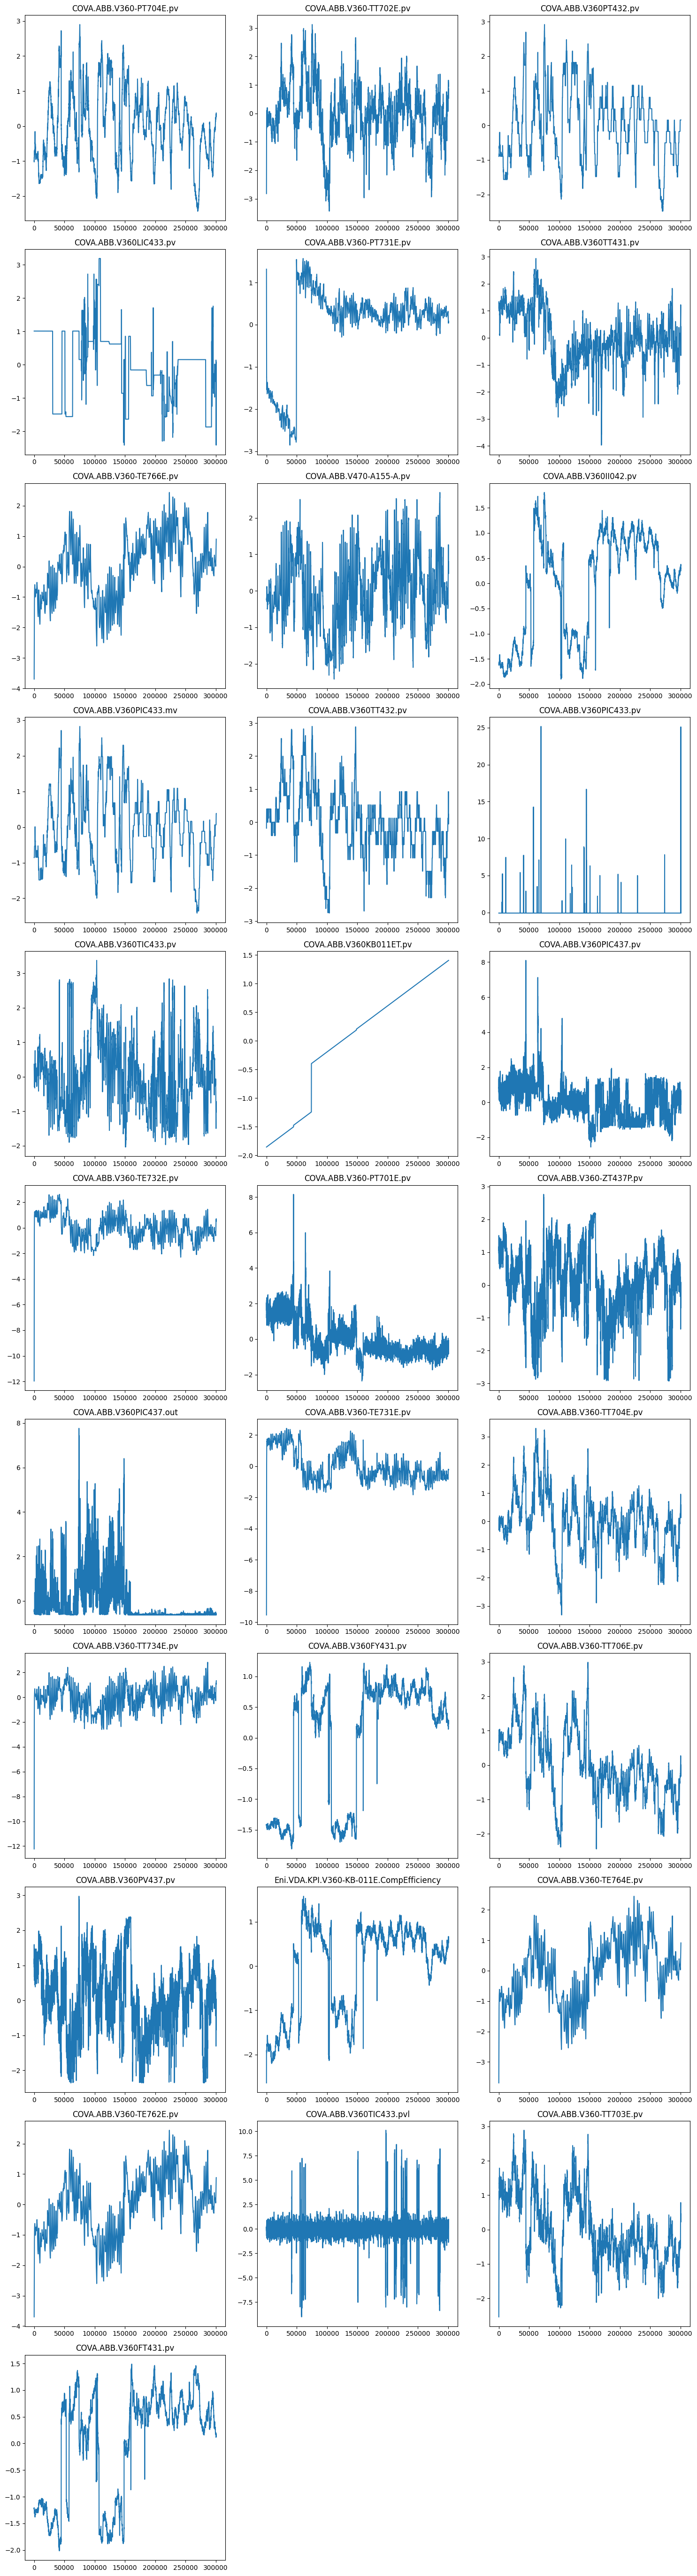

In [28]:
plot_columns_in_grid(scaled_train_df, target_cols)

In [29]:
import gc
gc.collect()

104918

# ***GMM*** - *Gaussian Mixture Model* (Baseline)

As a baseline we are using a **GMM**, namely a a probabilistic model that represents data as a mixture of multiple Gaussian distributions, each defined by its mean and covariance. It is often used for clustering, density estimation, or modeling complex distributions

In [30]:
# Define the parameter grid
param_grid = {'n_components': [2, 4, 8, 16]}

gmm = GaussianMixture(2)

opt = GridSearchCV(
    estimator=gmm,
    param_grid=param_grid,
    cv=3,
    verbose=3,    # Set to 3 for detailed logs
    n_jobs=-1     # Use all available CPU cores
)

opt.fit(scaled_train_df[target_cols])


# Print the best parameters
#print(f'Best parameters: {opt.best_params_}')

Fitting 3 folds for each of 4 candidates, totalling 12 fits


GridSearchCV(cv=3, estimator=GaussianMixture(n_components=2), n_jobs=-1,
             param_grid={'n_components': [2, 4, 8, 16]}, verbose=3)

In [31]:
# This computes the log probability density of the data points in the test set
ldens = opt.score_samples(scaled_test_df[target_cols])
signal = pd.Series(index=test_df.index, data=-ldens)

## Find the best threshold

In [32]:
gmm_best_threshold, gmm_best_score = threshold_optimization(signal, test_df[target], method = 'bayesian')

/usr/local/lib/python3.10/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [-24.981408823440447] before, using random point [85791.55725298934]
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [-24.981408823440447] before, using random point [64450.43491328707]
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [-24.981408823440447] before, using random point [66254.88661754207]
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [-24.981408823440447] before, using random point [33534.08671777352]
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [-24.981408

In [33]:
gmm_best_score

0.6473773721416066

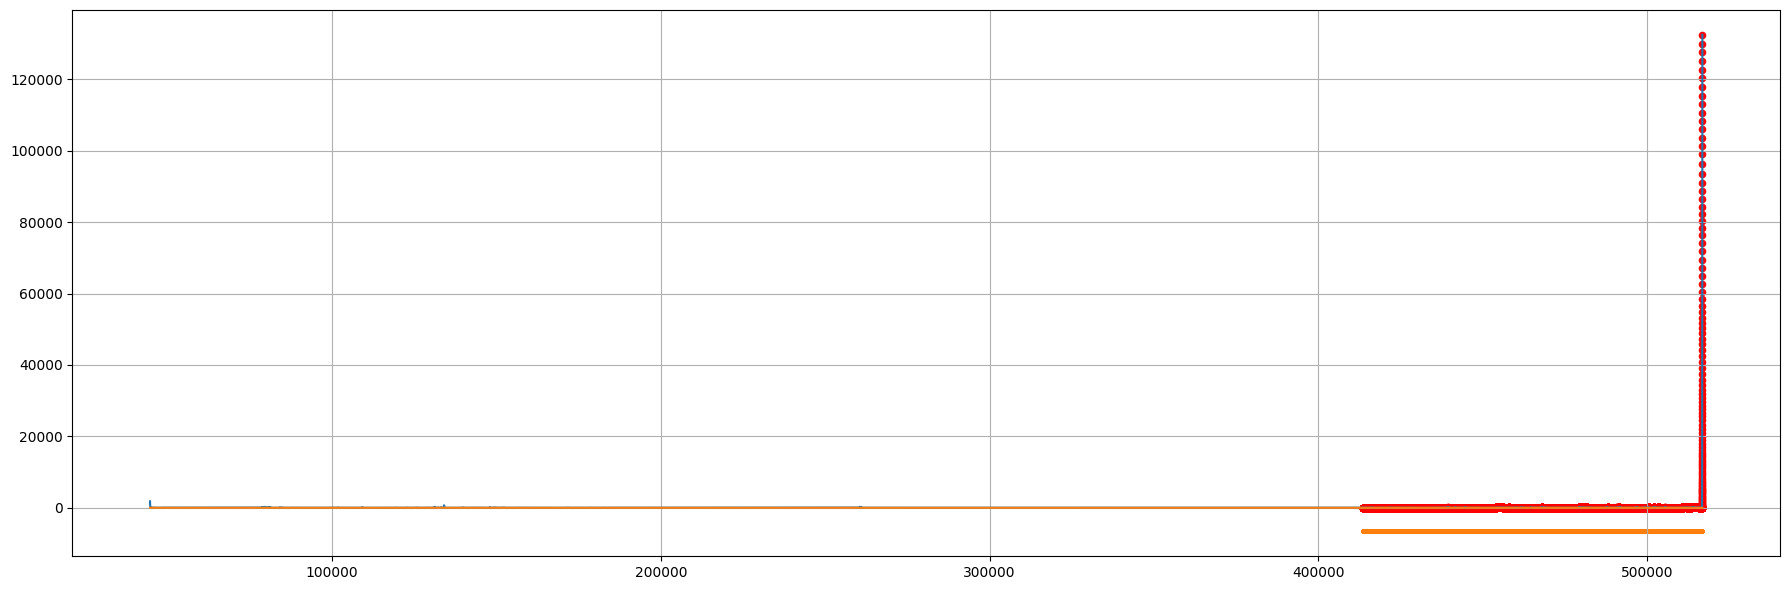

In [34]:
plot_signal(signal, test_df[target], figsize=figsize, threshold = gmm_best_threshold)

# Deep Learning Models
After the GMM baseline we trained 4 different models (AE, AE_LSTM, VAE and VAE_LSTM)

In [35]:
import gc
gc.collect()

3759

# Settings

In [36]:
batch_size = 32

if torch.cuda.is_available():
  device = torch.device("cuda:0")
else:
  device = torch.device("cpu")

# Define the dataset NOT SLIDED
train_df_dataset = MyDataset(scaled_train_df[target_cols], device=device)
test_df_dataset = MyDataset(scaled_test_df[target_cols], device=device)

# Define DataLoader
trdata_loader = DataLoader(train_df_dataset, batch_size=batch_size, shuffle=False)
tsdata_loader = DataLoader(test_df_dataset, batch_size=batch_size, shuffle=False)

In [37]:
input_size = len(target_cols)
hidden_size = 64
latent_size = 128
epochs = 10

# Train & Evaluation

In [38]:
true_labels = test_df[target]

## AE

 A simple **Autoencoder** with two main components:

- Encoder: Two linear layers compress the input to a latent space.
- Decoder: Two linear layers reconstruct the input from the latent space.
The model uses **Mean Squared Error** (MSE) for reconstruction loss, and training is handled with the Adam optimizer. It includes early stopping for efficiency, and there are methods for evaluation, prediction, and plotting loss history to monitor performance.

Output: A reconstructed version of the input and a reconstruction error signal with the same size of input.

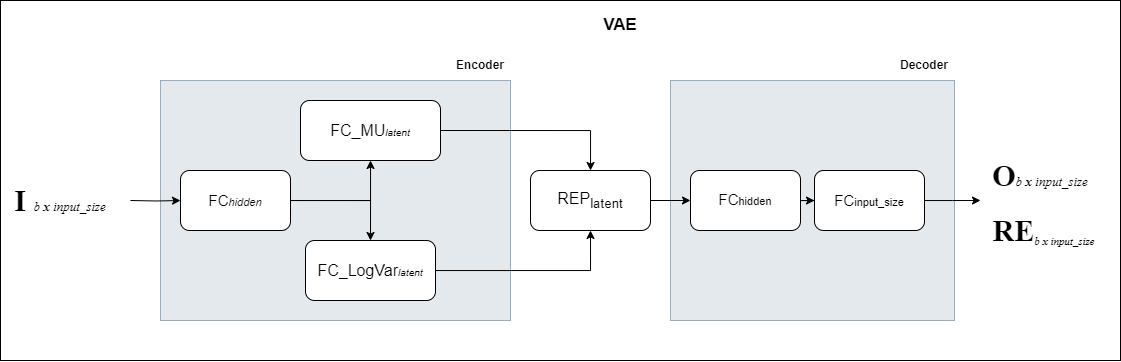

In [39]:
class AE(nn.Module):
    def __init__(self, input_size, hidden_size, latent_size, device=torch.device("cuda:0")):
        super(AE, self).__init__()
        self.device = device
        self.encoder = nn.Sequential(
            nn.Linear(input_size, hidden_size, device=self.device),
            nn.Linear(hidden_size, latent_size, device=self.device),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_size, hidden_size, device=self.device),
            nn.Linear(hidden_size, input_size, device=self.device),
        )
        self.criterion = nn.MSELoss()

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

    def loss_function(self,batch, recon_batch):
      loss = F.mse_loss(batch,recon_batch, reduction = 'none')
      return loss

    def criterion(self,x,recon_x):
        return self.loss_function(x,recon_x).mean()

    def evaluate(self, data_loader):
        self.eval()
        val_loss = 0.0
        with torch.no_grad():
            for batch in data_loader:
                recon_batch = self(batch)
                loss = self.criterion(batch, recon_batch)
                val_loss += loss.item() * batch.size(0)
        val_loss /= len(data_loader.dataset)
        return val_loss

    def fit(self, train_loader, num_epochs=30, batch_size=32, learning_rate=0.001, patience=3, val_loader=None, plot_history=False):
        train_loss_history = []
        val_loss_history = []

        opt = torch.optim.Adam(self.parameters(), lr=learning_rate)
        best_loss = float('inf')
        epochs_no_improve = 0

        for epoch in range(num_epochs):
            self.train()
            train_loss = 0.0

            # Initialize the tqdm progress bar for the current epoch
            progress_bar = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{num_epochs}", leave=False)

            for batch in progress_bar:
                opt.zero_grad()
                batch = batch.to(self.device)
                recon_batch = self(batch)
                loss = self.criterion(batch, recon_batch)
                loss.backward()
                opt.step()

                # Update the training loss
                train_loss += loss.item() * batch.size(0)

                # Set the progress bar description with the current loss
                progress_bar.update()
                progress_bar.set_postfix(loss=loss.item())

            train_loss /= len(train_loader.dataset)
            train_loss_history.append(train_loss)

            # Validation step if a validation loader is provided
            if val_loader:
                val_loss = self.evaluate(val_loader)
                val_loss_history.append(val_loss)
                print(f'Epoch {epoch + 1}/{num_epochs}, Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}')
                loss_to_improve = val_loss
            else:
                print(f'Epoch {epoch + 1}/{num_epochs}, Loss: {train_loss:.4f}')
                loss_to_improve = train_loss

            # Early stopping mechanism
            if loss_to_improve < best_loss:
                best_loss = loss_to_improve
                epochs_no_improve = 0
                best_model_wts = self.state_dict()
            else:
                epochs_no_improve += 1

            if epochs_no_improve >= patience:
                print('Early stopping!')
                self.load_state_dict(best_model_wts)
                break

        # Plot history if required
        if plot_history:
            plt.figure(figsize=(14, 6))
            plt.plot(train_loss_history, label='Train Loss', color='red')
            if len(val_loss_history) > 0:
                plt.plot(val_loss_history, label='Val Loss', color='blue')
            plt.legend()
            plt.xlabel('Epochs')
            plt.ylabel('Loss')
            plt.grid(True)
            plt.title("AE Loss History")
            plt.show()

        return train_loss_history, val_loss_history

    def predict(self, data_loader):
        self.eval()
        predictions = []
        losses = []
        with torch.no_grad():
            for batch in data_loader:
                preds = self(batch)
                predictions.append(preds)
                g_loss = self.loss_function(batch, preds)
                losses.append(g_loss)
        return torch.cat(predictions, dim=0), torch.cat(losses)

In [40]:
# Define VAE model
ae = AE(input_size, hidden_size, latent_size, device = device).to(device)
_,_ = ae.fit(trdata_loader, num_epochs=epochs, plot_history = False)

Epoch 1/10, Loss: 0.0843


Epoch 2/10, Loss: 0.0608


Epoch 3/10, Loss: 0.0578


Epoch 4/10, Loss: 0.0427


Epoch 5/10, Loss: 0.0339


Epoch 6/10, Loss: 0.0293


Epoch 7/10, Loss: 0.0242


Epoch 8/10, Loss: 0.0218


Epoch 9/10, Loss: 0.0189


Epoch 10/10, Loss: 0.0180


In [41]:
ae_preds_test,ae_signal_test = ae.predict(tsdata_loader)

In [42]:
# Convert into dataframe
ae_preds_test = pd.DataFrame(ae_preds_test.cpu().detach().numpy(), columns = target_cols)
ae_signal_test_col = pd.Series(ae_signal_test.mean(dim = 0).cpu().detach().numpy(), index = target_cols)
ae_signal_test_row = pd.Series(ae_signal_test.mean(dim = 1).cpu().detach().numpy())
ae_signal_test = pd.DataFrame(ae_signal_test.cpu().detach().numpy(), columns = target_cols)

### Signal comparison (ground truth vs prediction)

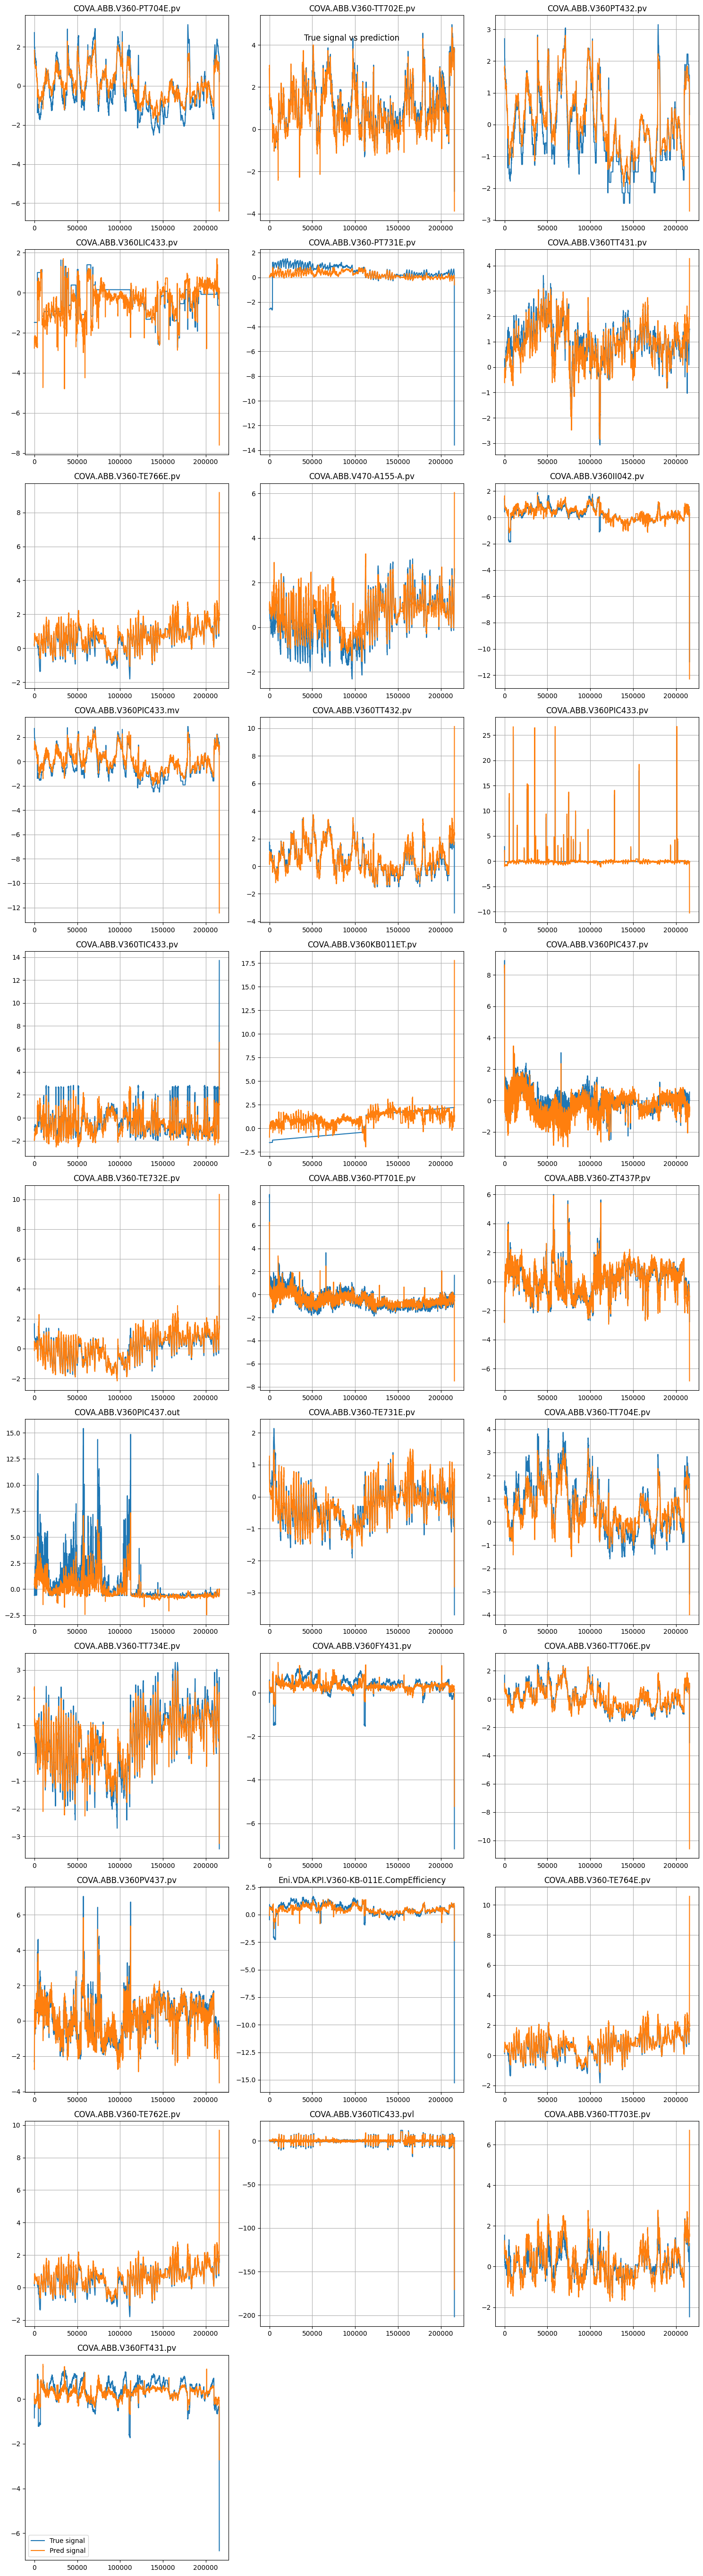

In [43]:
plot_predicted_on_real_signal(scaled_test_df[target_cols], ae_preds_test)

### Plot the signal reconstruction error by feature

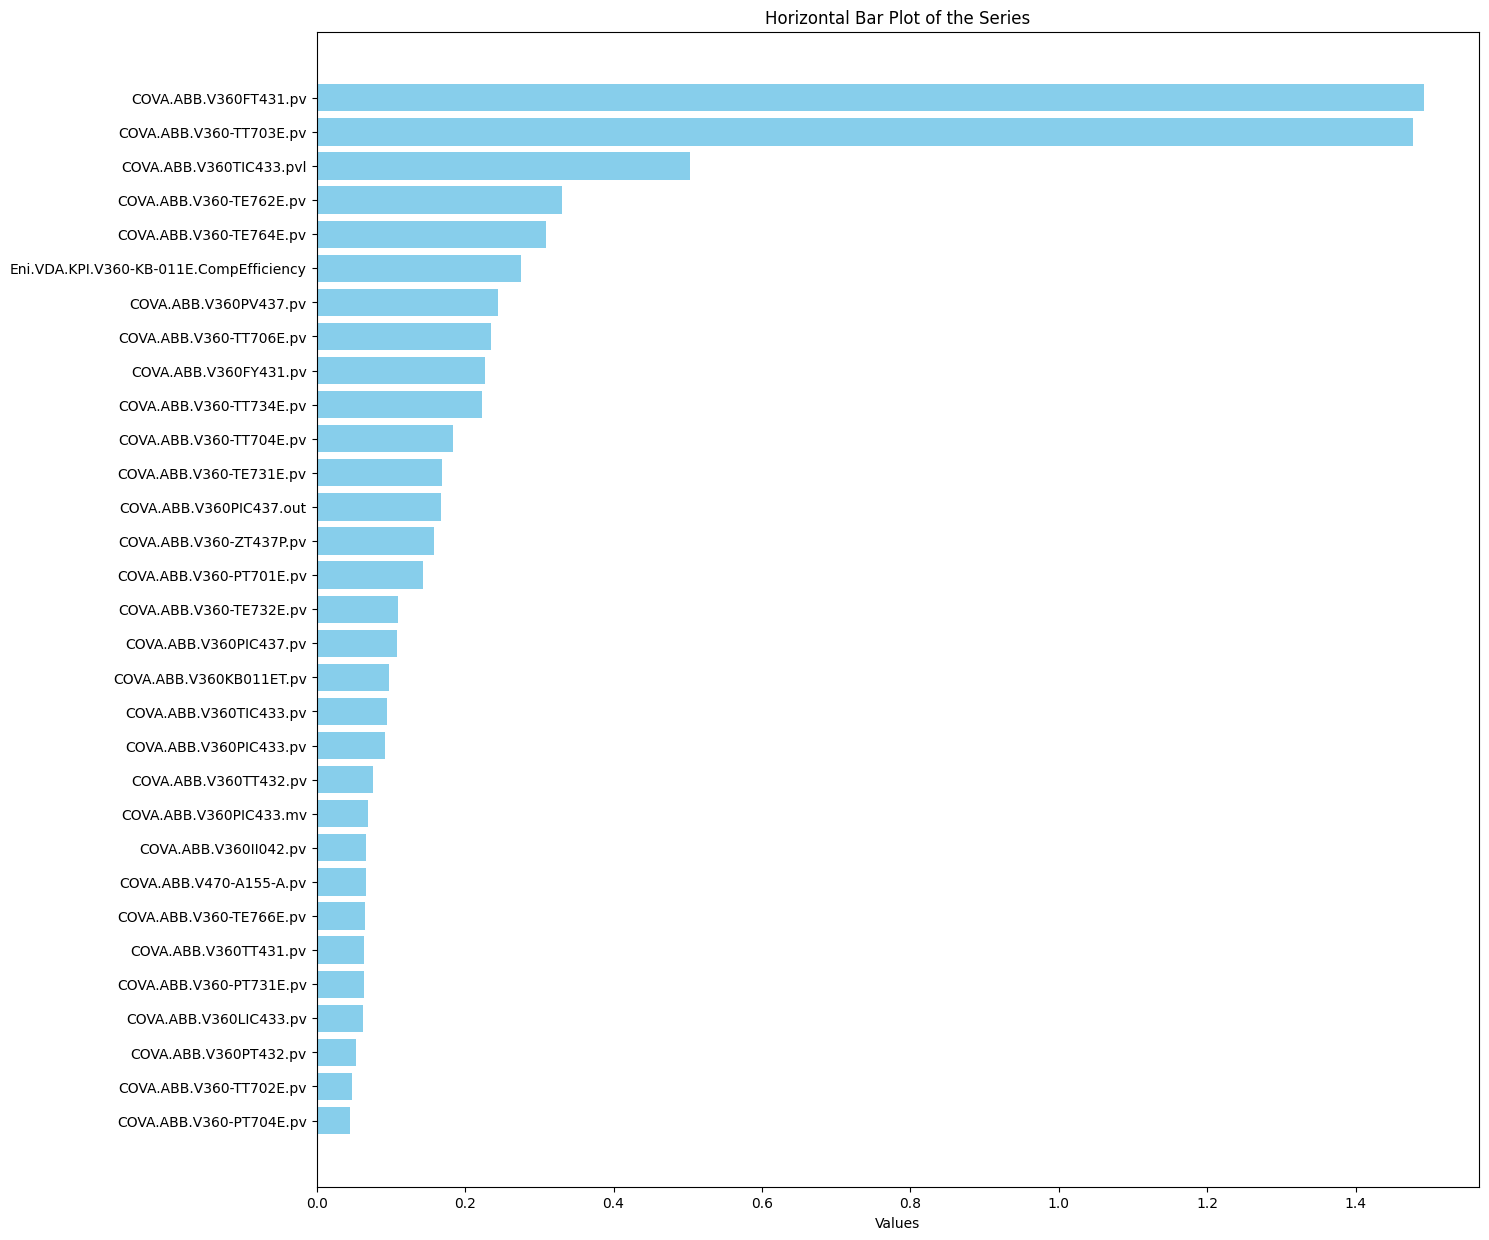

In [44]:
plt.figure(figsize=(15, 15))
plt.barh(target_cols, ae_signal_test_col.sort_values(ascending = True), color='skyblue')
plt.xlabel('Values')
plt.title('Horizontal Bar Plot of the Series')
plt.show()

### Find the best threshold
Threshold optimization using different methos

In [45]:
# Possible methods = ['bayesian' , 'simple' , 'cross_validation']
ae_best_threshold, ae_best_score = threshold_optimization(ae_signal_test_row, test_df[target], method = 'bayesian')

/usr/local/lib/python3.10/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [0.009409288875758648] before, using random point [56.287956608575485]
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [0.009409288875758648] before, using random point [42.29243334255863]
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [0.009409288875758648] before, using random point [43.47579405842513]
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [0.009409288875758648] before, using random point [22.017470124451503]
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [0.00

In [46]:
ae_best_score

0.6473773721416066

### Plot the reconstruction error with anomaly threshold

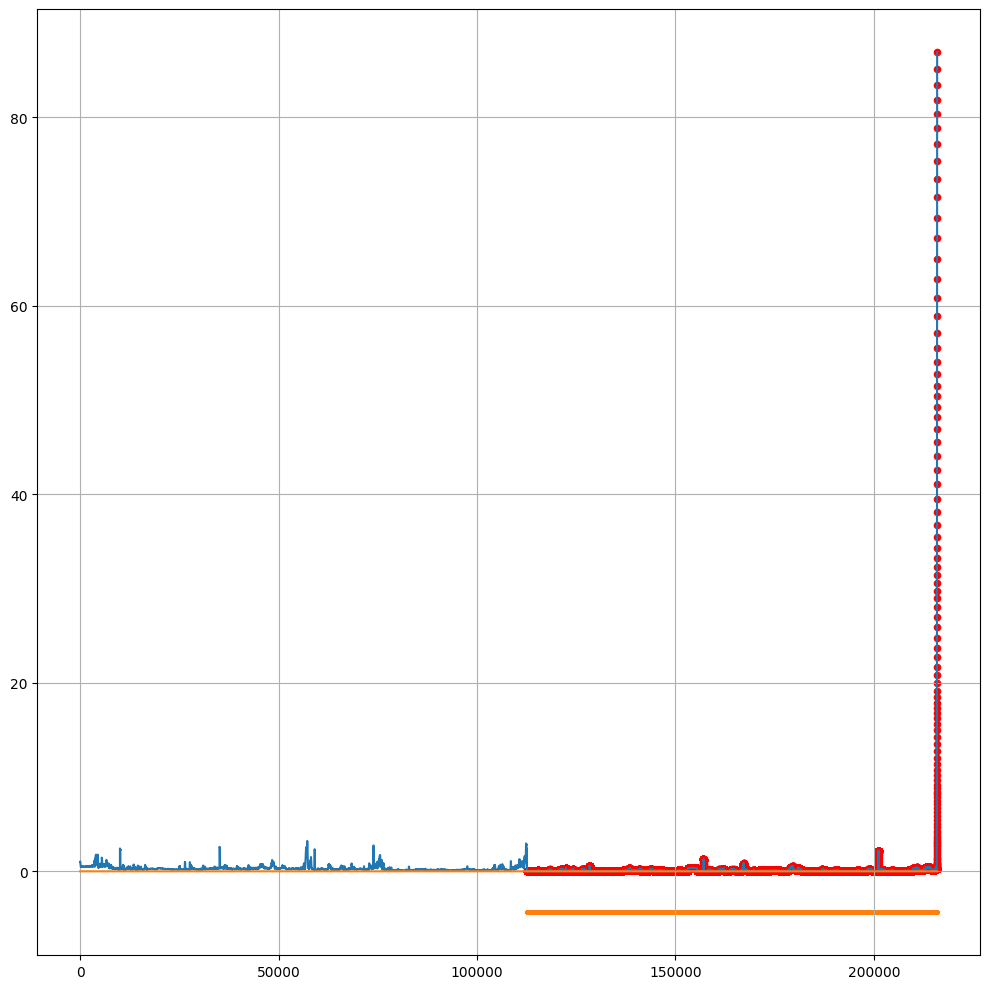

In [47]:
plot_signal(ae_signal_test_row, labels =true_labels ,threshold = ae_best_threshold)